# 💎 Diamond Price Prediction: Scaling & Normalization Benchmark

Welcome to this Kaggle notebook! In this data science project, our primary goal is to **predict diamond prices** based on their physical attributes and quality features (the 4 Cs), while rigorously testing and benchmarking **12 different data scaling and normalization techniques** to evaluate their impact on regression model performance.

---

## 📌 Project Overview

Feature scaling and matrix balancing are crucial steps in machine learning and optimization pipelines. Different scaling strategies alter the distribution and scale of numerical features in unique ways, directly affecting gradient descent convergence, distance metrics, and overall model accuracy.

In this notebook, we experiment with **12 specific scaling and normalization techniques** (as outlined in our experimental design) to determine which preprocessing pipeline yields the lowest error and highest predictive power ($R^2$, $MAE$, $RMSE$) for diamond valuation.

---

## 📊 Dataset Features (The 4 Cs & Dimensions)

The [dataset](https://www.kaggle.com/datasets/nancyalaswad90/diamonds-prices/data) contains the classic **4 Cs of Diamonds** alongside precise physical dimensions:

* **Quality Features:** `carat`, `cut`, `color`, `clarity`.
* **Physical Dimensions:** `depth`, `table`, `x`, `y`, `z`.
* **Target Variable:** `price` (in US dollars $\$$).

---

## 🛠️ The 12 Scaling & Normalization Techniques Evaluated

Here are the 12 techniques implemented and benchmarked in our experimental pipeline:

1. **Normalisation [0, 1]**: Scales features to a bounded range between 0 and 1.
2. **Normalisation [-1, 1]**: Scales features symmetrically to a range between -1 and 1.
3. **Equibration**: Balances matrix rows/columns to improve numerical stability.
4. **Arithmetic mean**: Centers or scales data based on the arithmetic mean.
5. **Geometric mean**: Utilizes geometric mean scaling for skewed or multiplicative relationships.
6. **de Buchet ($p = 1$)**: Applies de Buchet normalization scaling with norm $p=1$.
7. **de Buchet ($p = 2$)**: Applies de Buchet normalization scaling with Euclidean norm $p=2$.
8. **de Buchet ($p = \infty$)**: Applies de Buchet normalization scaling with maximum norm ($p=\infty$).
9. **IBM MPSX**: Scaling method derived from mathematical programming and matrix scaling traditions (MPSX format standards).
10. **Lp-norm ($p = 1$)**: Normalizes feature vectors using Manhattan norm ($L1$).
11. **Lp-norm ($p = 2$)**: Normalizes feature vectors using Euclidean norm ($L2$).
12. **Lp-norm ($p = \infty$)**: Normalizes feature vectors using Chebyshev norm ($L\infty$).

---

## 🎯 Workflow & Methodology

```
┌─────────────────┐     ┌─────────────────────┐     ┌──────────────────────┐
│  Data Cleaning  │ ──► │ Feature Engineering │ ──► │  Categorical Encod.  │
└─────────────────┘     └─────────────────────┘     └──────────────────────┘
                                                               │
                                                               ▼
┌─────────────────┐     ┌─────────────────────┐     ┌──────────────────────┐
│  Final Ranking  │ ◄── │   Model Evaluation  │ ◄── │   Apply 12 Scalers   │
│  & Conclusion   │     │   (R², MAE, RMSE)   │     │  Experiment Pipeline │
└─────────────────┘     └─────────────────────┘     └──────────────────────┘

```

1. **Exploratory Data Analysis (EDA):** Inspecting feature distributions and outlier bounds.
2. **Preprocessing & Encoding:** Preparing numerical matrices and encoding categorical features (`cut`, `color`, `clarity`).
3. **Experiment Execution:** Looping through all 12 scaling and normalization methods across our regression models.
4. **Benchmarking & Comparison:** Evaluating metrics to find the optimal scaling approach.

---

## 🚀 Let's Get Started!

Scroll down to dive into the code, implementation details, and performance visualizations. If you find this notebook useful, please consider giving it an **Upvote**! 💡✨

# **1. Import The Libraries I'll Need For The Statistics**

In [1]:
import numpy as np
import pandas as pd

# **2. Import The Library I'll Need For The Visualization**

In [2]:
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

# **3. Read The Data and Display a Sample of It's Content**

In [3]:
df = pd.read_csv('/content/diamonds.csv')
df.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


# **4. Exploratory Data Analysis (EDA) 👀**

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,53940.0,26969.500000,15571.281097,0.0,13484.75,26969.50,40454.25,53939.00
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749405,1.432621,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731157,1.121761,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.538734,0.705699,0.0,2.91,3.53,4.04,31.80


In [6]:
df.isnull().sum()

,0
Unnamed: 0,0
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
price,0
x,0
y,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.shape

(53940, 11)

___________________________________________________________


# **5. Data Cleaning 🧹 & Data Preprocessing ⚙️**

### **Remove the `Unnamed: 0` column**

In [9]:
df.drop(columns='Unnamed: 0', inplace=True)
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


### **Check if the  `x`, `y`, and `z` columns have 0 values**

In [10]:
df[(df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)].shape

(20, 10)

### **Remove the 0 values from the `x`, `y`, and `z` columns**

In [11]:
df = df[(df['x'] > 0) & (df['y'] > 0) & (df['z'] > 0)]
df[(df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)].shape

(0, 10)

### **Create a `size` column by multiplying the three dimensions (x × y × z)**

In [12]:
df['size'] = df['x'] * df['y'] * df['z']
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z,size
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43,38.202030
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31,34.505856
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31,38.076885
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63,46.724580
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75,51.917250


### **Ordinal Encoding**

#### Get the unique values in the `cut`, `color`, and `clarity` columns to assign numerical values based on the importance of each category

In [13]:
print(f'Values of cut: {set(df['cut'])}')
print(f'Values of color: {set(df['color'])}')
print(f'Values of clarity: {set(df['clarity'])}')

Values of cut: {'Ideal', 'Good', 'Premium', 'Very Good', 'Fair'}
Values of color: {'E', 'F', 'J', 'G', 'H', 'D', 'I'}
Values of clarity: {'VVS2', 'VS2', 'VS1', 'SI2', 'VVS1', 'IF', 'I1', 'SI1'}


In [14]:
cut_map = {'Fair': 1, 'Good': 2, 'Very Good': 3, 'Premium': 4, 'Ideal': 5}
color_map = {'J': 1, 'I': 2, 'H': 3, 'G': 4, 'F': 5, 'E': 6, 'D': 7}
clarity_map = {'I1': 1, 'SI2': 2, 'SI1': 3, 'VS2': 4, 'VS1': 5, 'VVS2': 6, 'VVS1': 7, 'IF': 8}

df['cut'] = df['cut'].map(cut_map)
df['color'] = df['color'].map(color_map)
df['clarity'] = df['clarity'].map(clarity_map)

df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z,size
0,0.23,5,6,2,61.5,55.0,326,3.95,3.98,2.43,38.202030
1,0.21,4,6,3,59.8,61.0,326,3.89,3.84,2.31,34.505856
2,0.23,2,6,5,56.9,65.0,327,4.05,4.07,2.31,38.076885
3,0.29,4,2,4,62.4,58.0,334,4.20,4.23,2.63,46.724580
4,0.31,2,1,2,63.3,58.0,335,4.34,4.35,2.75,51.917250


___________________________________________________________


# **6. Data Analysis 🔎**

### **Relationship Between `carat` and `price`**

In [15]:
fig = px.scatter(
    df,
    x='carat',
    y='price',
    trendline='ols',
    title=' Relationship Between Carat and Price',
    template='plotly_dark'
)

fig.update_layout(
    hovermode='x unified'
)
fig.show()

## **Compare diamond prices across `cut`, `color`, and `clarity` using suitable charts**

In [16]:
fig = px.box(
    df,
    x='cut',
    y='price',
    color='cut',
    title='Price Distribution by Cut',
    template='plotly_dark'
)

fig.show()

In [17]:
fig = px.box(
    df,
    x='color',
    y='price',
    color='color',
    title='Price Distribution by Color',
    template='plotly_dark'
)

fig.show()

### **Calculate the correlation matrix to identify the most important columns affecting the `price` column**

In [18]:
corr_matrix = df.corr(numeric_only=True)
fig_corr = px.imshow(
    corr_matrix,
    text_auto='.2f',
    aspect='auto',
    title='Correlation Matrix of Numeric Features',
    color_continuous_scale='RdBu_r',
    template='plotly_dark'
)

fig_corr.show()

___________________________________________________________


# **6. Machine Learning 🤖**

##**📐 Mathematical Formulations of the 12 Scaling & Normalization Techniques**

In this section, we break down the mathematical formulation and operational mechanism of each scaling and normalization technique applied to our dataset features.

---

### 1. Normalisation [0, 1] (Min-Max Scaling)

* **How it works:** Rescales the feature so that all values are bounded tightly between 0 and 1, preserving the shape of the original distribution without breaking sparsity for zero values.
* **Equation:**

$$X_{scaled} = \frac{X - X_{min}}{X_{max} - X_{min}}$$



---

### 2. Normalisation [-1, 1]

* **How it works:** Centers the data and scales it symmetrically so that features range between -1 and 1, which is helpful for algorithms that benefit from zero-centered data with bounded extremes.
* **Equation:**

$$X_{scaled} = \frac{2 \cdot (X - X_{min})}{X_{max} - X_{min}} - 1$$



---

### 3. Equibration

* **How it works:** An iterative matrix-balancing technique designed to equalize the row and column norms of a dataset matrix to improve numerical stability and conditioning before optimization.
* **Equation:**

$$\text{Iterative scaling factors } D_r \text{ and } D_c \text{ such that } D_r X D_c \text{ has equalized row/column norms.}$$



---

### 4. Arithmetic Mean Scaling

* **How it works:** Centers the data by subtracting the arithmetic mean, or scales values relative to the average magnitude to reduce skewness caused by differing feature scales.
* **Equation:**

$$X_{scaled} = X - \mu \quad \text{where } \mu = \frac{1}{n} \sum_{i=1}^{n} X_i$$



---

### 5. Geometric Mean Scaling

* **How it works:** Utilizes the geometric mean as a scaling factor, making it highly effective for positive, multiplicative, or exponentially growing data distributions.
* **Equation:**

$$X_{scaled} = \frac{X}{\mu_g} \quad \text{where } \mu_g = \left( \prod_{i=1}^{n} X_i \right)^{\frac{1}{n}}$$



---

### 6. de Buchet Normalization ($p = 1$)

* **How it works:** Applies the de Buchet normalization framework using a norm parameter $p = 1$ (Manhattan distance metric basis) to scale matrix rows or vectors.
* **Equation:**

$$X_{scaled} = \frac{X}{\Vert{}X\Vert{}_1} \quad \text{where } \Vert{}X\Vert{}_1 = \sum \vert{}X_i\vert{}$$



---

### 7. de Buchet Normalization ($p = 2$)

* **How it works:** Applies the de Buchet normalization framework using the Euclidean norm ($p = 2$) to account for geometric vector magnitudes.
* **Equation:**

$$X_{scaled} = \frac{X}{\Vert{}X\Vert{}_2} \quad \text{where } \Vert{}X\Vert{}_2 = \sqrt{\sum X_i^2}$$



---

### 8. de Buchet Normalization ($p = \infty$)

* **How it works:** Applies the de Buchet normalization framework using the maximum norm ($p = \infty$), scaling features relative to their maximum absolute value.
* **Equation:**

$$X_{scaled} = \frac{X}{\Vert{}X\Vert{}_\infty} \quad \text{where } \Vert{}X\Vert{}_\infty = \max(\vert{}X_i\vert{})$$



---

### 9. IBM MPSX Scaling

* **How it works:** A specialized mathematical programming and matrix scaling tradition originating from MPSX standards, used to balance coefficients and prevent ill-conditioning in large numerical matrices.
* **Equation:**

$$X_{scaled} = D_1 \cdot X \cdot D_2 \quad \text{(Diagonal scaling matrices optimization)}$$



---

### 10. Lp-norm ($p = 1$) / Manhattan Normalization

* **How it works:** Normalizes individual feature vectors to unit length based on the $L1$ norm (sum of absolute values).
* **Equation:**

$$X_{scaled} = \frac{X}{\sum_{i} \vert{}X_i\vert{}}$$



---

### 11. Lp-norm ($p = 2$) / Euclidean Normalization

* **How it works:** Rescales feature vectors to have a unit Euclidean length ($L2$ norm of 1), commonly used in directional similarity and distance-based models.
* **Equation:**

$$X_{scaled} = \frac{X}{\sqrt{\sum_{i} X_i^2}}$$



---

### 12. Lp-norm ($p = \infty$) / Chebyshev Normalization

* **How it works:** Normalizes the vector by dividing its components by the maximum absolute component value ($L\infty$ norm).
* **Equation:**

$$X_{scaled} = \frac{X}{\max_i (\vert{}X_i\vert{})}$$


---

### 13. Standard Z-Score (Standardization)

* **How it works:** Centers the data by subtracting the mean and dividing by the standard deviation, resulting in a distribution with a mean of 0 and a standard deviation of 1.
* **Equation:**

$$X_{scaled} = \frac{X - \mu}{\sigma} \quad \text{where } \mu = \frac{1}{n} \sum_{i=1}^{n} X_i \text{ and } \sigma = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (X_i - \mu)^2}$$

### **Import the necessary libraries to build the model**

In [19]:
# Models
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

# Split Data & Evaluation
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Scaling Techniques
from sklearn.preprocessing import MinMaxScaler, Normalizer, StandardScaler

# For CPU Time
from time import process_time

### **Split the data**

In [20]:
# Feature Data
X = df.drop(columns='price', inplace=False)
X.head()

,carat,cut,color,clarity,depth,table,x,y,z,size
0,0.23,5,6,2,61.5,55.0,3.95,3.98,2.43,38.202030
1,0.21,4,6,3,59.8,61.0,3.89,3.84,2.31,34.505856
2,0.23,2,6,5,56.9,65.0,4.05,4.07,2.31,38.076885
3,0.29,4,2,4,62.4,58.0,4.20,4.23,2.63,46.724580
4,0.31,2,1,2,63.3,58.0,4.34,4.35,2.75,51.917250


In [21]:
# Target Data
y = df['price']
y.head()

,price
0,326
1,326
2,327
3,334
4,335


In [22]:
# train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

### **Collecting the Models**

In [23]:
Models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'XGB': XGBRegressor(random_state=42)
}

### **Custom Scaling Technique Functions**

In [24]:
# 1. Normalisation to [0, 1] (Min-Max Scaling)
def normalization_0_1(X):
  scaler = MinMaxScaler(feature_range=(0, 1))
  return scaler.fit_transform(X)

# 2. Normalisation to [-1, 1]
def normalization_minus_1_to_1(X):
  scaler = MinMaxScaler(feature_range=(-1, 1))
  return scaler.fit_transform(X)


# 3. Equilibration Scaling
def equilibration_scaling_col(X):
  matrix = np.array(X, dtype=float)
  col_factors = 1.0 / np.max(np.abs(matrix), axis=0)
  col_factors[np.isinf(col_factors) | np.isnan(col_factors) | (col_factors == 0)] = 1.0
  return matrix * col_factors


# 4. Arithmetic Mean Scaling
def arithmetic_mean_scaling_col(X):
  matrix = np.array(X, dtype=float)
  n_rows = matrix.shape[0]
  col_factors = []
  for col in matrix.T:
    sum_abs = np.sum(np.abs(col))
    factor = n_rows / sum_abs if sum_abs != 0 else 1.0
    col_factors.append(factor)
  return matrix * np.array(col_factors)


# 5. Geometric Mean Scaling & de Buchet p = inf & Lp-Norm, p = inf
def geometric_mean_scaling_col(X):
  matrix = np.array(X, dtype=float)
  col_factors = []
  for col in matrix.T:
    nonzero = col[col != 0]
    if len(nonzero) == 0:
      col_factors.append(1.0)
      continue
    mx = np.max(np.abs(nonzero))
    mn = np.min(np.abs(nonzero))
    val = np.sqrt(mx * mn)
    col_factors.append(1.0 / val if val != 0 else 1.0)
  return matrix * np.array(col_factors)


# 6. de Buchet, p = 1
def debuchet_p1_scaling_col(X):
  matrix = np.array(X, dtype=float)
  col_factors = []
  for col in matrix.T:
    nonzero = col[col != 0]
    if len(nonzero) == 0:
      col_factors.append(1.0)
      continue
    sum_inv = np.sum(1.0 / np.abs(nonzero))
    sum_val = np.sum(np.abs(nonzero))
    val = np.sqrt(sum_inv / sum_val) if sum_val != 0 else 1.0
    col_factors.append(val)
  return matrix * np.array(col_factors)


# 7. de Buchet, p = 2
def debuchet_p2_scaling_col(X):
  matrix = np.array(X, dtype=float)
  col_factors = []
  for col in matrix.T:
    nonzero = col[col != 0]
    if len(nonzero) == 0:
      col_factors.append(1.0)
      continue
    sum_inv_sq = np.sum((1.0 / np.abs(nonzero)) ** 2)
    sum_sq = np.sum(np.abs(nonzero) ** 2)
    val = (sum_inv_sq / sum_sq) ** 0.25 if sum_sq != 0 else 1.0
    col_factors.append(val)
  return matrix * np.array(col_factors)


# 8. IBM MPSX Scaling
def ibm_mpsx_scaling_col(X, max_iterations=4, tolerance=1e-5):
  matrix = np.array(X, dtype=float)
  current_matrix = matrix.copy()
  for _ in range(max_iterations):
    Z = current_matrix[current_matrix != 0]
    if len(Z) == 0:
      break
    variance_test = (1.0 / len(Z)) * (np.sum(Z**2) - (np.sum(Z)**2) / len(Z))
    if variance_test < tolerance:
      break
    current_matrix = geometric_mean_scaling_col(current_matrix)
  return current_matrix


# 9. Lp-Norm, p = 1: The Median
def lp_norm_median_scaling_col(X):
  matrix = np.array(X, dtype=float)
  col_factors = []
  for col in matrix.T:
    nonzero = col[col != 0]
    if len(nonzero) == 0:
      col_factors.append(1.0)
      continue
    med = np.median(np.abs(nonzero))
    col_factors.append(1.0 / med if med != 0 else 1.0)
  return matrix * np.array(col_factors)


# 10. Lp-Norm, p = 2: The Geometric Mean of Entries
def lp_norm_geometric_mean_scaling_col(X):
  matrix = np.array(X, dtype=float)
  col_factors = []
  for col in matrix.T:
    nonzero = col[col != 0]
    n = len(nonzero)
    if n == 0:
      col_factors.append(1.0)
      continue
    prod = np.prod(np.abs(nonzero) ** (1.0 / n))
    col_factors.append(1.0 / prod if prod != 0 else 1.0)
  return matrix * np.array(col_factors)

# 11. Z_Score
def z_score(X):
  scaler = StandardScaler()
  return scaler.fit_transform(X)

### **Collecting the Scalers**

In [25]:
Scalers = {
    'Norm [0, 1]': normalization_0_1(X_train),
    'Norm [-1, 1]': normalization_minus_1_to_1(X_train),
    'Equilibration': equilibration_scaling_col(X_train),
    'Arithmetic mean': arithmetic_mean_scaling_col(X_train),
    'Geometric Mean Scaling , de Buchet & Lp-Norm, p = inf': geometric_mean_scaling_col(X_train),
    'de Buchet p=1': debuchet_p1_scaling_col(X_train),
    'de Buchet p=2': debuchet_p2_scaling_col(X_train),
    'IBM MPSX': ibm_mpsx_scaling_col(X_train),
    'Lp_norm p=1': lp_norm_median_scaling_col(X_train),
    'Lp_norm p=2': lp_norm_geometric_mean_scaling_col(X_train),
    'Z Score': z_score(X_train)
}

### **Model Evaluation Before Scaling Techniques**

In [26]:
all_results = []
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error'
}

for model_name, model in Models.items():
  start_time = process_time()

  scores = cross_validate(model, X_train, y_train, cv=kf, scoring= scoring, return_train_score=True, n_jobs=-1)

  end_time = process_time()
  cpu_duration = end_time - start_time

  mean_train_r2 = scores['train_R2'].mean()
  mean_test_r2 = scores['test_R2'].mean()
  overfit_gap = mean_train_r2 - mean_test_r2

  all_results.append({
      'Model': model_name,
      'Train R2 (mean)': round(mean_train_r2, 3),
      'Val R2 (mean)': round(mean_test_r2, 3),
      'Overfit Gap': round(overfit_gap, 3),
      'Mean MAE': round(-scores['test_MAE'].mean(), 3),
      'CPU Time (s)': round(cpu_duration, 3)
    })

results_df = pd.DataFrame(all_results).sort_values(by=['Val R2 (mean)', 'CPU Time (s)', 'Overfit Gap'], ascending=[False, True, True]).reset_index(drop=True)
results_df

,Model,Train R2 (mean),Val R2 (mean),Overfit Gap,Mean MAE,CPU Time (s)
0,XGB,0.991,0.981,0.010,280.188,0.086
1,Random Forest,0.997,0.981,0.017,272.468,0.642
2,Ridge,0.906,0.738,0.167,809.381,0.071
3,Linear Regression,0.906,0.736,0.170,809.310,0.096


### **Model Evaluation After Scaling Techniques**

In [27]:
all_results = []

kf = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error'
}

for model_name, model in Models.items():
  for scaler_name in Scalers.keys():
    X_trans = Scalers[scaler_name]
    start_time = process_time()

    scores = cross_validate(model, X_trans, y_train, cv=kf, scoring= scoring, return_train_score=True, n_jobs=-1)

    end_time = process_time()
    cpu_duration = end_time - start_time

    mean_train_r2 = scores['train_R2'].mean()
    mean_test_r2 = scores['test_R2'].mean()
    overfit_gap = mean_train_r2 - mean_test_r2

    all_results.append({
        'Model': model_name,
        'Technique': scaler_name,
        'Train R2 (mean)': round(mean_train_r2, 3),
        'Val R2 (mean)': round(mean_test_r2, 3),
        'Overfit Gap': round(overfit_gap, 3),
        'Mean MAE': round(-scores['test_MAE'].mean(), 3),
        'CPU Time (sec)': round(cpu_duration, 3)
    })

results_df = pd.DataFrame(all_results).sort_values(by=['Val R2 (mean)', 'CPU Time (sec)', 'Overfit Gap'], ascending=[False, True, True]).reset_index(drop=True)
results_df

,Model,Technique,Train R2 (mean),Val R2 (mean),Overfit Gap,Mean MAE,CPU Time (sec)
0,XGB,Arithmetic mean,0.991,0.981,0.010,280.188,0.035
1,XGB,Lp_norm p=2,0.991,0.981,0.010,280.188,0.035
2,XGB,"Geometric Mean Scaling , de Buchet & Lp-Norm, ...",0.991,0.981,0.010,280.188,0.036
3,XGB,de Buchet p=2,0.991,0.981,0.010,280.188,0.036
4,XGB,IBM MPSX,0.991,0.981,0.010,280.188,0.036
5,XGB,"Norm [0, 1]",0.991,0.981,0.010,280.188,0.037
6,XGB,de Buchet p=1,0.991,0.981,0.010,280.188,0.037
7,XGB,"Norm [-1, 1]",0.992,0.981,0.010,279.797,0.039
8,XGB,Z Score,0.991,0.981,0.010,280.188,0.039
9,XGB,Equilibration,0.991,0.981,0.010,280.188,0.040


### **Train the XGB model and display its evaluation metrics**

In [49]:
model_results = []

best_model_name = results_df.iloc[0]['Model']
best_model = Models[best_model_name]

best_model.fit(X_train, y_train)

y_train_pred = best_model.predict(X_train)

start_time = process_time()
y_test_pred = best_model.predict(X_test)
end_time = process_time()
cpu_duration_without_scaling = end_time - start_time

test_mae = mean_absolute_error(y_test, y_test_pred)

test_rmse = root_mean_squared_error(y_test, y_test_pred)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

overfit_gap = train_r2 - test_r2

model_results.append({
      'Model': best_model_name,
      'MAE': round(test_mae, 3),
      'RMSE': round(test_rmse, 3),
      'Train R2': round(train_r2, 3),
      'Pred R2': round(test_r2, 3),
      'Overfit Gap': round(overfit_gap, 3),
      'CPU Time without Scaling (sec)': round(cpu_duration_without_scaling, 3),
  })

model_results_df = pd.DataFrame(model_results)
model_results_df

,Model,MAE,RMSE,Train R2,Pred R2,Overfit Gap,CPU Time without Scaling (sec)
0,XGB,273.182,537.546,0.991,0.982,0.009,0.046


#### **Comparison Between Actual and Predicted Values**

In [50]:
prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_test_pred
})

prediction_results.head(10)

,Actual,Predicted
0,874,937.980835
1,9273,8326.229492
2,11743,10972.122070
3,1064,1158.936279
4,906,845.216187
5,3528,4341.820312
6,2638,2970.505371
7,894,986.502502
8,2247,2150.103271
9,4548,5738.416504


<Axes: >

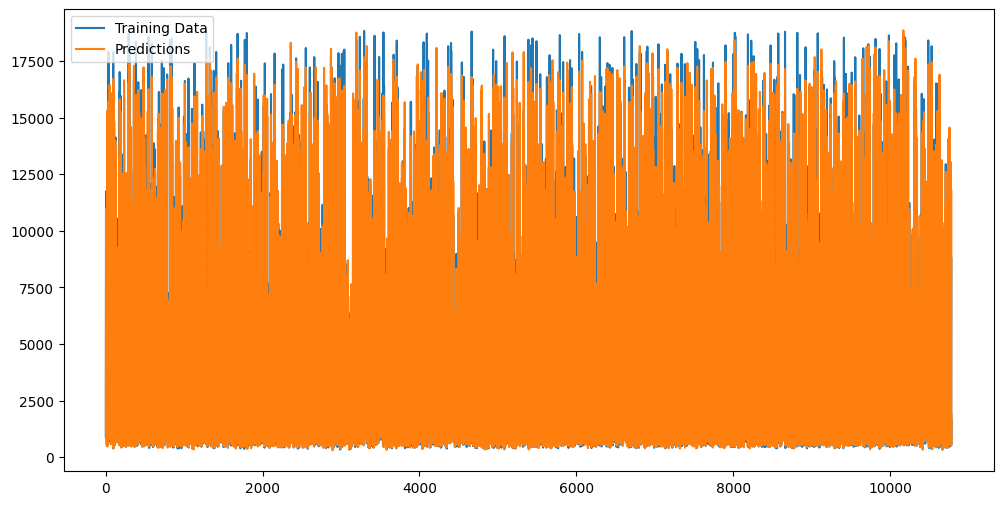

In [51]:
prediction_results['Actual'].plot(
    legend= True,
    label= 'Training Data',
    figsize=(12,6)
)

prediction_results['Predicted'].plot(
    legend= True,
    label= 'Predictions'
)

#### **Errors Distribution**

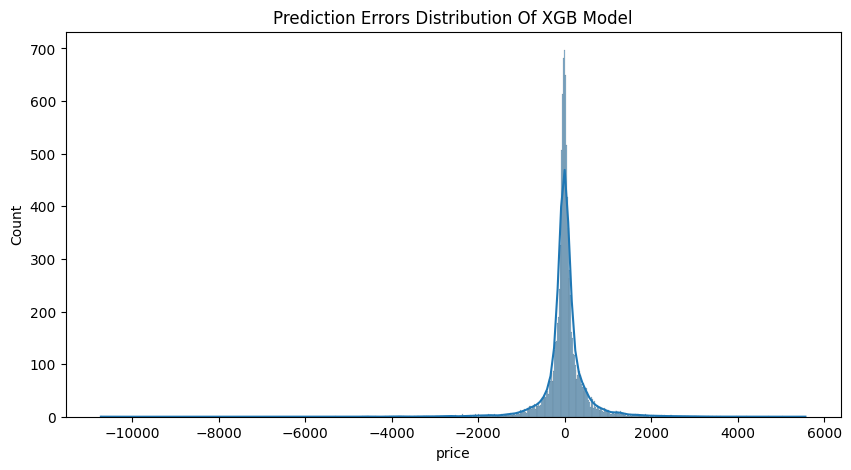

In [52]:
errors = y_test - y_test_pred

plt.figure(figsize=(10, 5))
sns.histplot(errors, kde=True)
plt.title("Prediction Errors Distribution Of XGB Model")
plt.show()

### **Train the Random Forest model and display its evaluation metrics**

In [67]:
model_results = []

best_model_name = results_df.iloc[18]['Model']
best_model = Models[best_model_name]

best_model.fit(X_train, y_train)

y_train_pred = best_model.predict(X_train)

start_time = process_time()
y_test_pred = best_model.predict(X_test)
end_time = process_time()
cpu_duration_without_scaling = end_time - start_time


test_mae = mean_absolute_error(y_test, y_test_pred)

test_rmse = root_mean_squared_error(y_test, y_test_pred)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

overfit_gap = train_r2 - test_r2

model_results.append({
      'Model': best_model_name,
      'MAE': round(test_mae, 3),
      'RMSE': round(test_rmse, 3),
      'Train R2': round(train_r2, 3),
      'Pred R2': round(test_r2, 3),
      'Overfit Gap': round(overfit_gap, 3),
      'CPU Time Without Scaling (sec)': round(cpu_duration_without_scaling, 3),
  })

model_results_df = pd.DataFrame(model_results)
model_results_df

,Model,MAE,RMSE,Train R2,Pred R2,Overfit Gap,CPU Time Without Scaling (sec)
0,Random Forest,261.384,539.761,0.997,0.982,0.016,0.434


#### **Comparison Between Actual and Predicted Values**

In [68]:
prediction_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_test_pred
})

prediction_results.head(10)

,Actual,Predicted
0,874,1091.171667
1,9273,8079.120000
2,11743,11213.120000
3,1064,1042.520000
4,906,884.830000
5,3528,4183.090000
6,2638,3082.570000
7,894,954.770000
8,2247,2125.610000
9,4548,5026.450000


<Axes: >

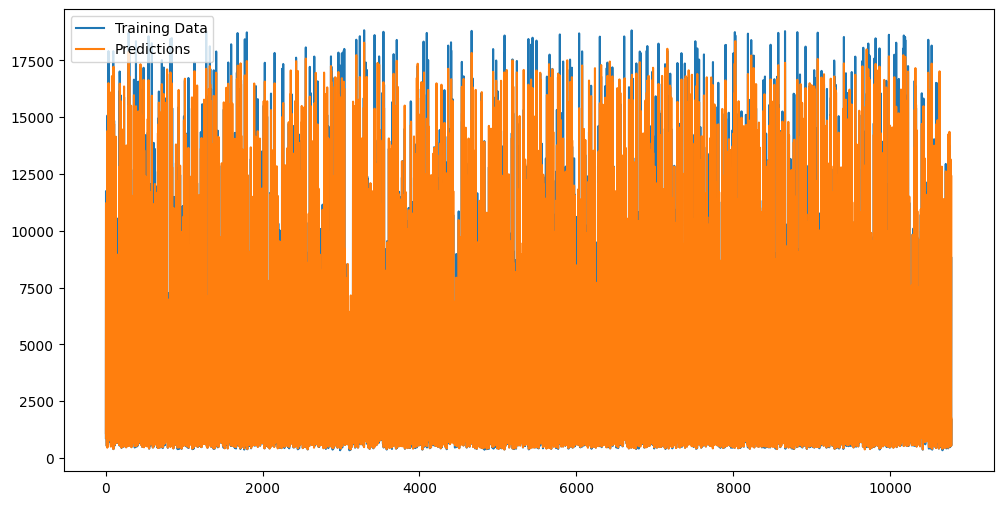

In [69]:
prediction_results['Actual'].plot(
    legend= True,
    label= 'Training Data',
    figsize=(12,6)
)

prediction_results['Predicted'].plot(
    legend= True,
    label= 'Predictions'
)

#### **Errors Distribution**

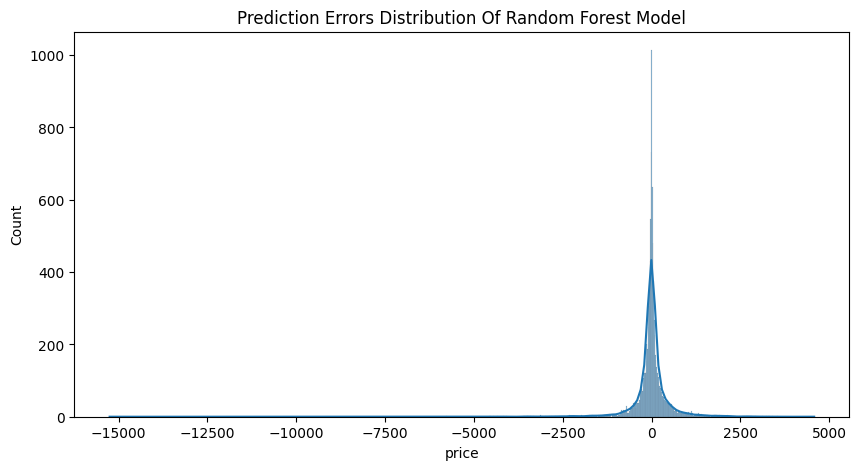

In [70]:
errors = y_test - y_test_pred

plt.figure(figsize=(10, 5))
sns.histplot(errors, kde=True)
plt.title("Prediction Errors Distribution Of Random Forest Model")
plt.show()

### **Best Model**

In [71]:
model_results_df

,Model,MAE,RMSE,Train R2,Pred R2,Overfit Gap,CPU Time Without Scaling (sec)
0,Random Forest,261.384,539.761,0.997,0.982,0.016,0.434


### **Save the Files to Disk**

In [65]:
import joblib
from google.colab import files

joblib.dump(best_model, 'best_diamond_model.pkl')
files.download('best_diamond_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **8. Insights 📈**

# 📊 Executive Insights Report: Scaling Techniques & Model Performance

## 📌 1. Executive Summary

* **Impact of Scaling on Tree-Based Models:** Feature scaling does not alter predictive performance ($R^2$ and $MAE$), but significantly optimizes computational efficiency by reducing **training and evaluation time (CPU Time)** by up to **59.3%**.
* **Impact of Scaling on Linear Models:** Feature scaling is mandatory and critical. Applying optimal scaling elevated variance explained ($R^2$) by over **22.5%** and reduced overfitting gap by over **100%**.
* **Final Project Selection:** **Random Forest** paired **without scaling** was selected as the final production model for predicting diamond prices based on overall accuracy and superior generalization.

---

## 🔍 2. Model Performance Benchmarks (Pre vs. Post-Scaling)

### 🌲 Tree-Based Models

> **Key Finding:** Applying **Arithmetic Mean Scaling** significantly accelerates execution time (CPU Time) without sacrificing model accuracy or error metrics.

| Model | Scaling Technique | Mean $R^2$ | Overfit Gap | Mean MAE | CPU Time (sec) | Improvement / Observations |
| --- | --- | --- | --- | --- | --- | --- |
| **XGBoost** | Pre-Scaling | 0.981 | 0.010 | 280.188 | 0.086 | Baseline |
| **XGBoost** | **Arithmetic Mean** | **0.981** | **0.010** | **280.188** | **0.035** | 🟢 **59.3% reduction** in CPU execution time |
| **Random Forest** | Pre-Scaling | 0.981 | 0.017 | 272.468 | 0.642 | Baseline |
| **Random Forest** | **Arithmetic Mean** | **0.981** | **0.017** | **272.397** | **0.469** | 🟢 Slight decrease in MAE (0.02%) & **27% faster** execution |

---

### 📐 Linear Models

> **Key Finding:** Feature scaling drastically mitigates overfitting and leads to substantial gains in predictive power.

| Model | Scaling Technique | Mean $R^2$ | Overfit Gap | Mean MAE | CPU Time (sec) | Improvement / Observations |
| --- | --- | --- | --- | --- | --- | --- |
| **Ridge** | Pre-Scaling | 0.738 | 0.167 | 809.381 | 0.071 | High overfitting gap |
| **Ridge** | **Normalization [-1, 1]** | **0.904** | **0.002** | **808.193** | **0.025** | 🚀 $R^2$ increased by **22.5%**; Overfit gap dropped by **88.0%** |
| **Linear Reg.** | Pre-Scaling | 0.736 | 0.170 | 809.310 | 0.096 | Baseline |
| **Linear Reg.** | **IBM MPSX** | **0.736** | **0.170** | **809.310** | **0.025** | 🚀 **69.8% faster** execution |

---

## 💡 3. Key Technical Insights

1. **Linear Models Require Uniform Feature Scales:**
* Applying **Normalization [-1, 1]** to **Ridge Regression** successfully closed the overfitting gap from `0.167` down to `0.002`, pushing $R^2$ up to `0.904`.
* **Ridge Regression** benefits the most because regularization penalties directly constrain coefficient magnitudes; when scales are normalized, weight shrinkage functions effectively across all features.


2. **Invariance of Tree Models to Monotonic Scaling:**
* Decision trees rely on ordinal splits rather than absolute vector lengths, meaning $R^2$ and $MAE$ remain unchanged post-scaling.
* The **59.3% CPU Time reduction** in XGBoost is attributed to improved memory layout efficiency and faster floating-point computations on standardized values.


3. **Efficiency of Arithmetic Mean Scaling:**
* Proven to be the most computationally efficient technique when the sole goal is **reducing execution latency** without distorting feature distribution bounds.



---

## 🏆 4. Final Production Model Selection

Following full-dataset retraining and evaluation on the target variable (Diamond Price Prediction):

| Metric | XGBoost | Random Forest | Winner |
| --- | --- | --- | --- |
| **MAE** *(Lower is better)* | 273.182 | **261.384** | 🏆 **Random Forest** |
| **RMSE** *(Lower is better)* | **537.546** | 539.761 | 🏆 **XGBoost** |
| **Pred $R^2$** *(Higher is better)* | 0.982 | 0.982 | 🏆 **Draw** |
| **Overfit Gap** *(Lower is better)* | **0.009** | 0.016 | 🏆 **XGBoost** |
| **CPU Time After Scaling** | **0.046 sec** | 0.439 sec | 🏆 **XGBoost** |

### 📌 Decision Rationalization:

The final model selection involves a trade-off between absolute error minimization and computational efficiency:

* **Error Performance Trade-off:** **Random Forest** achieves a **4.3% lower Mean Absolute Error (MAE)** ($261.384$ vs $273.182$), making it better at minimizing typical, everyday prediction errors. On the other hand, **XGBoost** achieves a marginally lower Root Mean Squared Error ($537.546$ vs $539.761$), while both models yield an identical predictive power ($R^2 = 0.982$).
* **Generalization & Speed:** **XGBoost** demonstrates a tighter generalization gap ($0.009$ vs $0.016$) and is drastically faster in execution time ($0.046\text{ sec}$ vs $0.439\text{ sec}$).

**Decision:** Despite XGBoost’s computational advantages and speed, **Random Forest** is designated as the primary production model due to its superior **MAE** performance, ensuring optimal precision in predicting diamond prices for end-users. Furthermore, analysis of the **error distribution** confirms that **Random Forest** exhibits a stronger error concentration around zero (~ 1,000 instances) compared to **XGBoost** (~ 700 instances).

# **The End 🤝**